# Découvrir un arbre de décision avec les fleurs Iris

**Durée : 20 à 25 minutes.** Travail individuel ou en binôme.

Objectifs : distinguer variables d’entrée et catégorie, traduire un test en Python, entraîner un petit arbre et suivre son parcours pour prédire une espèce.

Dans Colab : **Fichier → Importer un notebook**, puis sélectionnez ce fichier. Exécutez les cellules dans l’ordre avec le bouton ▶ ou `Maj + Entrée`. Les bibliothèques et les données sont disponibles dans Colab ; aucun fichier de données à télécharger.

Les trois espèces sont *Iris setosa*, *Iris versicolor* et *Iris virginica*. Nous utilisons seulement deux mesures des pétales, en centimètres. Les noms latins et les mots-clés Python sont conservés.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree

iris = load_iris()
noms_variables = ["Longueur du pétale (cm)", "Largeur du pétale (cm)"]
noms_especes = ["setosa", "versicolor", "virginica"]
X = iris.data[:, 2:4]  # Les deux colonnes des pétales
y = iris.target       # Les codes des espèces : 0, 1 et 2
tableau = pd.DataFrame(X, columns=noms_variables)
tableau["Espèce"] = [noms_especes[code_espece] for code_espece in y]
print("Nombre de fleurs :", len(tableau))
display(tableau.head())

Nombre de fleurs : 150


,Longueur du pétale (cm),Largeur du pétale (cm),Espèce
0,1.4,0.2,setosa
1,1.4,0.2,setosa
2,1.3,0.2,setosa
3,1.5,0.2,setosa
4,1.4,0.2,setosa


## 1. Identifier la tâche (3 minutes)

1. Que représente une ligne du tableau ?
2. Quelles sont les variables d’entrée ? Quelle est la catégorie à prédire ?
3. Est-ce une classification ou une régression ? Un apprentissage supervisé ou non supervisé ? Justifiez.

**Vos réponses :**
1. Une ligne représente une instance de fleur classifiée.
2. Les variables sont la longueur et la largeur du pétale. La catégorie à prédire est le nom de l'espèce (setosa, versicolor ou virginica).
3. C'est une classification car la prédiction qui est faite est discrète et non continue. C'est un apprentissage supervisé car on donne au modèle des exemples déjà classifiés à partir desquels il va extrapoler et faire des prédictions.

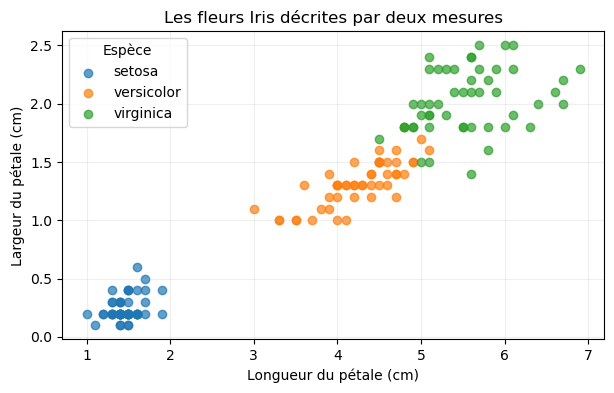

In [2]:
plt.figure(figsize=(7, 4))
for numero, espece in enumerate(noms_especes):
    selection = y == numero
    plt.scatter(X[selection, 0], X[selection, 1], label=espece, alpha=0.7)
plt.xlabel(noms_variables[0])
plt.ylabel(noms_variables[1])
plt.title("Les fleurs Iris décrites par deux mesures")
plt.legend(title="Espèce")
plt.grid(alpha=0.2)
plt.show()

## 2. Écrire une première règle (5 minutes)

Sur ce graphique, les fleurs setosa ont des pétales courts. Complétez la fonction ci-dessous :

- si la longueur est **inférieure ou égale à 2 cm**, renvoyer `"setosa"` ;
- sinon, renvoyer `"autre espèce"`.

Indice : utilisez `if`, `else`, `<=` et `return`. Remplacez la ligne `return "À compléter"`. Respectez l’indentation.

Prévoyez les résultats pour 1,5 cm, 2 cm et 4,5 cm avant d’exécuter la cellule. Cette règle est écrite par vous ; elle n’a pas été apprise automatiquement.

In [3]:
def premiere_regle(longueur):
    # À compléter avec un test et deux réponses possibles.
    if longueur <= 2:
        return "sestosa"
    else:
        return "autre espèce"

for longueur in [1.5, 2.0, 4.5]:
    print(f"Longueur : {longueur} cm → {premiere_regle(longueur)}")

Longueur : 1.5 cm → sestosa
Longueur : 2.0 cm → sestosa
Longueur : 4.5 cm → autre espèce


## 3. Apprendre un petit arbre (5 minutes)

Le code suivant est fourni. `fit(X, y)` construit les tests de l’arbre à partir des mesures et des espèces connues. `max_depth=2` limite à deux le nombre maximal de tests sur un chemin. `random_state=42` fixe le hasard de l’algorithme pour obtenir le même arbre dans un même environnement.

Contrairement à votre fonction, les variables et les seuils des tests sont choisis pendant l’apprentissage.

Nous utilisons ici les 150 fleurs pour découvrir le fonctionnement du modèle. **Ce notebook ne mesure pas sa performance sur de nouvelles données.**

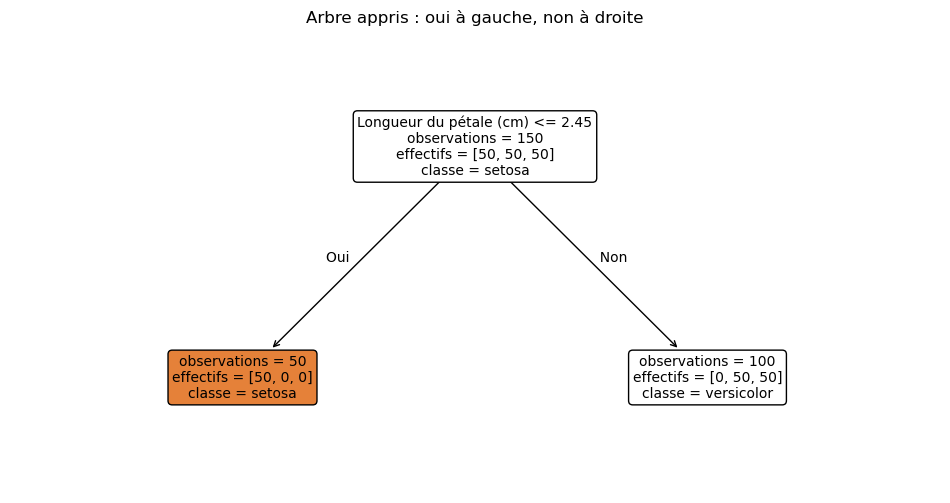

In [8]:
modele = DecisionTreeClassifier(max_depth=1, random_state=42)
modele.fit(X, y)

plt.figure(figsize=(12, 6))
boites = plot_tree(
    modele, feature_names=noms_variables, class_names=noms_especes,
    filled=True, impurity=False, rounded=True, fontsize=10
)
# Traduire les légendes produites par la bibliothèque.
for boite in boites:
    texte = boite.get_text()
    for original, traduction in [("samples", "observations"), ("value", "effectifs"),
                                   ("class", "classe"), ("True", "Oui"), ("False", "Non")]:
        texte = texte.replace(original, traduction)
    boite.set_text(texte)
plt.title("Arbre appris : oui à gauche, non à droite")
plt.show()

**Lire les boîtes :** le premier texte d’un nœud interne est le test. « observations » est le nombre de fleurs du nœud. « effectifs » donne les nombres par espèce, dans l’ordre **setosa, versicolor, virginica**. « classe » est l’espèce majoritaire. Une feuille ne comporte plus de test.

4. Quelle variable et quel seuil sont utilisés à la racine ?
5. Combien l’arbre a-t-il de feuilles ?
6. Trouvez une feuille contenant plusieurs espèces. Pourquoi peut-elle tout de même prédire une classe ?

**Vos réponses :**

4. A la racine, la variable utilisée est "longueur du pétale" et le seuil 2.45
5. 3 feuilles
6. Elle peut prédire une classe car elle identifie l'espèce majoritaire satisfaisant certains critères. 

## 4. Prédire une espèce (5 minutes)

Une nouvelle fleur possède un pétale de **4,5 cm de long et 1,4 cm de large**.

7. Suivez les tests de l’arbre à la main et notez l’espèce prédite **avant** d’exécuter la cellule.
8. Complétez `nouvelle_fleur` avec ces deux valeurs, dans le bon ordre. Remplacez `None` par une liste de listes, par exemple `[[1.5, 0.2]]` pour une autre fleur.
9. Vérifiez si Python donne la même prédiction que vous. Cette prédiction garantit-elle l’espèce réelle ?

**Votre parcours et votre réponse :**

7. longueur <= 2.45 : non -> largeur <= 1.75 : oui -> virginica
9. Python a la même prédiction, non cela ne garantit pas l'espèce réelle.

In [6]:
nouvelle_fleur = [[4.5, 1.4]]  # À remplacer par [[longueur, largeur]]

if nouvelle_fleur is None:
    print("Complétez les deux mesures de la nouvelle fleur, puis relancez la cellule.")
else:
    code_predit = modele.predict(nouvelle_fleur)[0]
    print("Espèce prédite :", noms_especes[code_predit])

Espèce prédite : versicolor


## 5. Bilan (2 minutes)

Complétez : « Pendant l’apprentissage, le modèle reçoit … et … . Pendant la prédiction, il reçoit … et renvoie … . »

Expliquez en une phrase la différence entre votre règle de l’étape 2 et l’arbre appris à l’étape 3.

**Vos réponses :** …

Pendant l’apprentissage, le modèle reçoit X (caractéristiques d'un ensemble de fleurs) et y (les espèces associées à ces fleurs). Pendant la prédiction, il reçoit les caractéristiques d'une fleur (longeur et largeur de la fleur) et renvoie une catégorie (l'espèce de la fleur).

X = iris.data[:, 2:4]  # Les deux colonnes des pétales
y = iris.target       # Les codes des espèces : 0, 1 et 2

### Pour aller un peu plus loin, si vous avez terminé

Remplacez `max_depth=2` par `max_depth=1`, relancez l’apprentissage puis la prédiction. Combien de feuilles voyez-vous ? Quelles espèces cet arbre peut-il prédire ? Pourquoi ?

Un arbre plus grand n’est pas automatiquement meilleur pour de nouvelles données.

**Vos réponses :** …

On voit 2 feuilles car il n'y a que 1 condition donc elle est soit satisfaite soit non satifaite. Cet arbre peut uniquement prédire l'espèce setosa car uniquement cette espèce satifait cette condition.

Supports : *Cours_Apprentissage_Automatique_v2026_01_15.pdf* (apprentissage supervisé, classification et régression) ; *Arbres_v2026_10_01.pdf* (tests, racine, feuilles, majorité et Iris).